# GEOG 214A — Lab 1: VS Code and NASA Earthdata Access
**Name:** Houpu Li
**Course:** GEOG 214A, Fall 2026

AI usage statement: I used Claude (Anthropic) in this lab, mainly to help me understand data-storage concepts I was unfamiliar with, including bit depth and quantization, data types (e.g., uint8 vs. uint16), scale factors and offsets, band interleave (BSQ/BIL/BIP)

## Part 1. Python Crash Course
### 1.1 Numbers, Strings, and Booleans

In [1]:
dn = 214                     # a raw digital number -- int
reflectance = 0.342          # a physical, scaled value -- float
band_name = "B04"            # a band identifier -- str
is_saturated = dn >= 255     # a yes/no question -- bool

print(type(dn), type(reflectance), type(band_name), type(is_saturated))

<class 'int'> <class 'float'> <class 'str'> <class 'bool'>


### 1.2 Variables, Comments, and f-strings

In [2]:
bit_depth = 12                    # HLS/EMIT-class sensors are commonly 12-bit
max_dn = 2 ** bit_depth - 1        # ** is exponentiation; a 12-bit sensor tops out at 4095

print(f"A {bit_depth}-bit sensor saturates at a DN of {max_dn}.")

A 12-bit sensor saturates at a DN of 4095.


#### Required (8 pts)

In [3]:
# Pixel 1
red, nir = 0.08, 0.45
ndvi_1 = (nir - red) / (nir + red)

# Pixel 2
red, nir = 0.25, 0.28
ndvi_2 = (nir - red) / (nir + red)

print(f"Pixel 1 NDVI = {ndvi_1:.4f}")
print(f"Pixel 2 NDVI = {ndvi_2:.4f}")

Pixel 1 NDVI = 0.6981
Pixel 2 NDVI = 0.0566


### 1.3 Lists

In [4]:
hls_bands = ["B02", "B03", "B04", "B05"]   # Blue, Green, Red, NIR -- the bands Part 3 downloads

print(hls_bands[0])       # first band  -> 'B02' (Blue)
print(hls_bands[-1])      # last band   -> 'B05' (NIR)
print(hls_bands[1:3])     # Green through Red (index 3, NIR, is excluded)
print(len(hls_bands))     # how many bands

B02
B05
['B03', 'B04']
4


### 1.4 Tuples

In [5]:
sb_bbox = (-119.90, 34.35, -119.60, 34.50)   # (west, south, east, north) -- same bbox as Session Setup below
west, south, east, north = sb_bbox            # unpacking

print(f"Study area spans {east - west:.2f} degrees of longitude and {north - south:.2f} of latitude.")

Study area spans 0.30 degrees of longitude and 0.15 of latitude.


### 1.5 Dictionaries

In [6]:
# A stand-in for the kind of nested metadata a real `earthaccess` granule hands you in Part 3
granule_metadata = {
    "ShortName": "HLSL30",
    "CloudCover": 12.4,
    "TemporalExtent": {"BeginningDateTime": "2023-06-01T18:32:11Z"},
}
print(granule_metadata["ShortName"])
print(granule_metadata["TemporalExtent"]["BeginningDateTime"])

# A dictionary of named field sites -- name -> (lon, lat)
study_sites = {
    "Ocean": (-119.7988, 34.3907),
    "Vegetation": (-119.85, 34.44),
    "Urban": (-119.70, 34.42),
}
print(study_sites["Vegetation"])

HLSL30
2023-06-01T18:32:11Z
(-119.85, 34.44)


#### Required (8 pts)

In [7]:
bands = {"red": 0.08, "green": 0.10, "nir": 0.45}

ndvi = (bands["nir"] - bands["red"]) / (bands["nir"] + bands["red"])
ndwi = (bands["green"] - bands["nir"]) / (bands["green"] + bands["nir"])

print(f"NDVI = {ndvi:.4f}")
print(f"NDWI = {ndwi:.4f}")

NDVI = 0.6981
NDWI = -0.6364


### 1.6 Comparisons and Booleans

In [8]:
cloud_cover = 12.4
is_usable = cloud_cover < 20
print("Usable scene?", is_usable)

dn = 255
is_saturated = dn >= (2 ** 8 - 1)   # true ceiling of an 8-bit sensor
print("Saturated pixel?", is_saturated)

Usable scene? True
Saturated pixel? True


### 1.7 for Loops and List Comprehensions

In [9]:
for band in hls_bands:
    print("Band:", band)

for site, (lon, lat) in study_sites.items():
    print(f"{site}: lon={lon}, lat={lat}")

# List comprehension -- pull the band number out of each name in one line
band_numbers = [int(b[1:]) for b in hls_bands]
print(band_numbers)

Band: B02
Band: B03
Band: B04
Band: B05
Ocean: lon=-119.7988, lat=34.3907
Vegetation: lon=-119.85, lat=34.44
Urban: lon=-119.7, lat=34.42
[2, 3, 4, 5]


### 1.8 Functions

In [10]:
def apply_scale_factor(dn, scale_factor=0.0001, fill_value=-9999):
    """Convert a raw digital number to a physical unit (e.g., reflectance)."""
    if dn == fill_value:
        return None   # a documented "no data" sentinel, not a real measurement
    return dn * scale_factor

print(apply_scale_factor(3420))
print(apply_scale_factor(-9999))

0.342
None


### 1.9 NumPy Arrays

In [11]:
import numpy as np

# A tiny stand-in for one corner of a real HLS band: a 4x4 grid of scaled-integer DNs
dn_array = np.array([
    [3120, 3180, 3050, 4200],
    [3090, 3110, 6200, -9999],  # -9999 here is a documented cloud fill value, not a real measurement
    [3200, 3250, 3300, 3280],
    [3000, 3050, 3100, 3150],
])

print("Shape:", dn_array.shape)     # (rows, cols)
print("Data type:", dn_array.dtype)

scale_factor = 0.0001               # same value you'll pull from the real HLS User Guide in Part 3
reflectance = dn_array * scale_factor   # vectorized -- every element scaled in one line, no loop
print(reflectance)

# Boolean masking -- flag anything above a physically sane reflectance ceiling
suspect = reflectance > 0.6
print("Suspect pixels:\n", suspect)

Shape: (4, 4)
Data type: int64
[[ 0.312   0.318   0.305   0.42  ]
 [ 0.309   0.311   0.62   -0.9999]
 [ 0.32    0.325   0.33    0.328 ]
 [ 0.3     0.305   0.31    0.315 ]]
Suspect pixels:
 [[False False False False]
 [False False  True False]
 [False False False False]
 [False False False False]]


#### Required (8 pts)

In [12]:
print("Fill mask:\n", dn_array == -9999)
print("Fill value(s):", dn_array[dn_array == -9999])

Fill mask:
 [[False False False False]
 [False False False  True]
 [False False False False]
 [False False False False]]
Fill value(s): [-9999]


## Part 2. Core Concepts

In [13]:
rows, cols, bands = 300, 200, 100   # rows ("lat"), cols ("lon"), band

# Index as (column, row, band), 0-based, so the first band of the first pixel is (0, 0, 0).

#### Required (7 pts)

In [14]:
n_pixels = rows * cols
n_elements = rows * cols * bands
print(f"Pixels (spatial locations): {n_pixels:,}")
print(f"Pixel-band elements:        {n_elements:,}")

Pixels (spatial locations): 60,000
Pixel-band elements:        6,000,000


**Answer:**  

A pixel is one spatial location, we totally have 300 × 200 = 60,000 pixels. Each pixel holds one value per band and each pixel carries 100 values. Thus the total pixel-band elements will be 300 × 200 × 100 = **6,000,000**.

#### Required (7 pts)

**1.What is the smallest unsigned integer data type (e.g. uint8, uint16) that can store these values at the stated precision?**
- Smallest data type: `uint8`.**, Reflectance from 0 to 1 at two decimal places has 101 possible values (0.00, 0.01, ..., 1.00).`uint8` stores 0–255 (256 values), which is enough to hold all 101.

**2.How many bits would the full image above (300 by 200 pixels and 100 bands) occupy using that data type?**
- Storage: 48,000,000 bits. The image has 300 × 200 × 100 = 6,000,000 pixel-band elements. With `uint8`, each value always takes 8 bits. So the total is 6,000,000 × 8 = 48,000,000 bits(since 8 bits = 1 byte, so the total data size should closee to 6,000,000 bytes ≈ 6 MB).

**3. Propose a reasonable scale value S in the equation DN = R * S + O, where DN is the stored digital number, R is reflectance, and O is an offset.**
- Scale: S = 100 because reflectance from 0 to 1 at two decimal places two-decimal. for example, 0.52 * 100 = 52, and 1.00 * 100 = 100.

**4. Is there any reason O would need to be nonzero here?**
- Offset: `O` = 0 is fine. because the smallest reflectance is 0, and 0 × 100 = 0, which presents No value becomes negative.

**5. A classmate proposes S = 500 and O = 0. Would that still work with the data type you chose? Explain why or why not.**
- Not it does not work, because the maximum reflection value 1 * 500 = 500 > 256(maximum of `unit8`)

### Byte order and band interleave

In [15]:
bytes_per_value = 2  # 16-bit unsigned integer = 2 bytes per stored value

#### Required (7 pts) — Storage size and interleave

In [16]:
total_bytes = rows * cols * bands * bytes_per_value
print(f"Total size: {total_bytes:,} bytes")

Total size: 12,000,000 bytes


**How many bytes does the image occupy on disk (report this in MB too)?**
- 300 × 200 × 100 × 2 = **12,000,000 bytes = 12 MB.

**Does the answer depend on whether the interleave is BIL or BSQ? **
- I think the `BSQ, BIL, and BIP`  only change the *order* in which the values are written (band by band, line by line, or pixel by pixel). The
interleave affects how fast certain read patterns are, but not the total number of bytes. And the size will not depend on interleave method.

## Part 3. Finding and Opening Data with `earthaccess`
### Session Setup

In [17]:
# %pip install -q earthaccess rasterio numpy matplotlib

In [18]:
# Quick environment check -- run this first.
import importlib.util

required = ["earthaccess", "rasterio", "numpy", "matplotlib"]
missing = [pkg for pkg in required if importlib.util.find_spec(pkg) is None]

if missing:
    print("Missing packages:", missing)
    print("Install them with:  pip install " + " ".join(missing))
else:
    print("All required packages are importable. You're ready to go.")

All required packages are importable. You're ready to go.


In [19]:
import earthaccess

# First run will prompt for your NASA Earthdata Login username/password and cache it in ~/.netrc
auth = earthaccess.login()

In [20]:
# Santa Barbara, CA study area: (west, south, east, north) in decimal degrees
sb_bbox = (-119.90, 34.35, -119.60, 34.50)

# A shared date range to search within -- adjust to taste. Using a wide range increases
# the odds of finding a cloud-free scene for every collection.
date_range = ("2023-01-01", "2023-12-31")

download_dir = "./data"

### Searching for Data
**1. By collection `short_name`:**

In [21]:
results = earthaccess.search_data(
    short_name="HLSL30",       # Harmonized Landsat Sentinel-2, Landsat-like product
    bounding_box=sb_bbox,
    temporal=date_range,
    count=5,
)
for g in results:
    print(g)

Collection: {'EntryTitle': 'HLS Landsat Operational Land Imager Surface Reflectance and TOA Brightness Daily Global 30m v2.0'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -120.25617766, 'Latitude': 34.20966703}, {'Longitude': -119.06537353, 'Latitude': 34.23552162}, {'Longitude': -119.09014717, 'Latitude': 35.2250277}, {'Longitude': -120.29518354, 'Latitude': 35.19820772}, {'Longitude': -120.25617766, 'Latitude': 34.20966703}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2023-01-08T18:34:30.538Z', 'EndingDateTime': '2023-01-08T18:34:54.429Z'}}
Size(MB): 200.40222358703613
Data: ['https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023008T183430.v2.0/HLS.L30.T11SKU.2023008T183430.v2.0.B09.tif', 'https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023008T183430.v2.0/HLS.L30.T11SKU.2023008T183430.v2.0.B01.tif', 'https://data.lp

**2. By keyword** (collection search first, then granule search):

In [22]:
# Step 1: find candidate collections by keyword (this is search_datasets, not search_data)
candidate_collections = earthaccess.search_datasets(
    keyword="MASTER",   # try other keywords too, e.g. "AVIRIS", "hyperspectral", "thermal"
    count=10,
)
for c in candidate_collections:
    print(c["umm"]["ShortName"], "-", c["umm"].get("EntryTitle"))

MASTER_L2_Emiss_LST_2489 - MASTER: Level 2 Emissivity and Land Surface Temperature
MASTER_L2_Emiss_LST_Overlays_2487 - MASTER: Image Overlays for Level 2 Emissivity and Land Surface Temperature
MASTER_L2_Emiss_LST_Quicklooks_2488 - MASTER: Quicklook Images for Level 2 Emissivity and Land Surface Temperature
MASTER_GEMx_Spring_2026_2513 - MASTER: Geological Earth Mapping Experiment (GEMx), Spring 2026
MASTER_GEMx_Summer_2025_2472 - MASTER: Geological Earth Mapping Experiment (GEMx), Summer 2025
MASTER_WDTS_Spring_2025_2471 - MASTER: Western Diversity Time Series Campaign, WDTS, Spring 2025
MASTER_Flightline_Locator_2151 - MASTER: Flight Line Geospatial Polygons and Contextual Data
MASTER_FireSense_Spring_2025_2439 - MASTER: FireSense, California and Southern US, Spring 2025
MASTER_WH2yMSIE_2024_2402 - MASTER: Westcoast-Heartland Hyperspectral Microwave Sensor Intensive Exp, Spring 2024
MASTER_WDTS_Spring_2024_2383 - MASTER: Western Diversity Time Series Campaign, WDTS, Spring 2024


In [23]:
# Step 2: once you've picked a collection above, search its granules by short_name --
# this is the same search_data() call pattern used throughout the rest of this notebook.
chosen_short_name = candidate_collections[0]["umm"]["ShortName"]

keyword_results = earthaccess.search_data(
    short_name=chosen_short_name,
    bounding_box=sb_bbox,
    temporal=date_range,
    count=10,
)
for g in keyword_results:
    print(g)

Collection: {'ShortName': 'MASTER_L2_Emiss_LST_2489', 'Version': '1'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -120.1327, 'Latitude': 34.4001}, {'Longitude': -119.7307, 'Latitude': 34.3367}, {'Longitude': -118.8023, 'Latitude': 38.1722}, {'Longitude': -119.2241, 'Latitude': 38.2379}, {'Longitude': -120.1327, 'Latitude': 34.4001}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2023-03-31T21:51:00Z', 'EndingDateTime': '2023-03-31T22:26:59Z'}}
Size(MB): 177.19725704193115
Data: ['https://data.ornldaac.earthdata.nasa.gov/ornl-cumulus-prod-protected/master/MASTER_L2_Emiss_LST/data/MASTERL2_2364100_12_20230331_2151_2226_V02_B200_SV01.hdf5']
Collection: {'ShortName': 'MASTER_L2_Emiss_LST_2489', 'Version': '1'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -120.1581, 'Latitude': 34.3217}, {'Longitude': -119.7453, 'Latitude': 34.2581}, {'L

#### Required (7 pts) — Inspect granule metadata before downloading

In [27]:
g = results[0]

print(f"SpatialExtent:\n{g['umm']['SpatialExtent']}")
print(f"\nTemporalExtent:\n{g['umm']['TemporalExtent']}")
print(f"\nSize: {g.size():.1f} MB")
links = "\n  ".join(g.data_links())
print(f"\nData links:\n  {links}")

SpatialExtent:
{'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -120.25617766, 'Latitude': 34.20966703}, {'Longitude': -119.06537353, 'Latitude': 34.23552162}, {'Longitude': -119.09014717, 'Latitude': 35.2250277}, {'Longitude': -120.29518354, 'Latitude': 35.19820772}, {'Longitude': -120.25617766, 'Latitude': 34.20966703}]}}]}}}

TemporalExtent:
{'RangeDateTime': {'BeginningDateTime': '2023-01-08T18:34:30.538Z', 'EndingDateTime': '2023-01-08T18:34:54.429Z'}}

Size: 200.4 MB

Data links:
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023008T183430.v2.0/HLS.L30.T11SKU.2023008T183430.v2.0.B09.tif
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023008T183430.v2.0/HLS.L30.T11SKU.2023008T183430.v2.0.B01.tif
  https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023008T183430.v2.0/HLS.L30.T11SKU.2023008T183430.v2.0.B04.tif
  ht

**Why would you want to know this information before you download the data?**
- This granule covers our Santa Barbara study area, was acquired on 2023-01-08, and is 200.4 MB across 15 files.

**Filtering by cloud cover**

In [29]:
clear_results = earthaccess.search_data(
    short_name="HLSL30",
    bounding_box=sb_bbox,
    temporal=date_range,
    cloud_cover=(0, 10),   # 0-10% cloud cover
    count=5,
)
print(f"{len(clear_results)} scene(s) under 10% cloud cover")

5 scene(s) under 10% cloud cover


#### Required (7 pts) 

**Compare the direct short_name search (Part 3, step 1 example) to the two-step keyword → collection → short_name workflow above. When would you reach for each one? What does the presence (or absence) of a stable short_name tell you about how "operational" vs. "campaign-based" a NASA data product is?**

- I would use a direct `short_name` search when I already know the product (e.g., HLSL30), but I would use the keyword workflow if I do not know the exact name, or for airborne campaign data like MASTER, where each campaign is a separate collection.
- A stable `short_name` like HLSL30 indicates an **operational** product(a long-term, regularly collected record under one name). Names that include a campaign, season, and year (e.g., `MASTER_FireSense_Spring_2025_2439`) indicate a **campaign-based** product(data collected only for a specific flight campaign, with limited coverage in space and time)

### Opening What You Found

In [32]:
demo_files = earthaccess.download(clear_results[:1], f"{download_dir}/demo")
print(demo_files)

QUEUEING TASKS | :   0%|          | 0/15 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/15 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/15 [00:00<?, ?it/s]

['data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B09.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.VAA.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B05.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B04.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B02.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.VZA.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B11.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B07.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B06.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B01.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B03.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.SZA.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.B10.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.Fmask.tif', 'data/demo/HLS.L30.T11SKU.2023024T183428.v2.0.SAA.tif']


In [33]:
import glob
import numpy as np
import rasterio
import os
band_path = sorted(glob.glob(f"{download_dir}/demo/*B04.tif"))[0]   # red band
print("File size (MB):", os.path.getsize(band_path) / 10**6)

with rasterio.open(band_path) as src:
    print("dtype:", src.dtypes[0])
    print("nodata / fill value:", src.nodata)
    print("shape (band, row, col):", (src.count, src.height, src.width))
    scale_factor = float(src.tags()["scale_factor"])   # read straight from the file, not hardcoded
    print("scale factor (from the file's own tags):", scale_factor)
    raw = src.read(1)

print("\nRaw stored values (min/max):", raw.min(), raw.max())

reflectance = raw.astype(float) * scale_factor
print("Scaled reflectance (min/max):", np.nanmin(reflectance), np.nanmax(reflectance))

File size (MB): 25.068232
dtype: int16
nodata / fill value: -9999.0
shape (band, row, col): (1, 3660, 3660)
scale factor (from the file's own tags): 0.0001

Raw stored values (min/max): -9999 13164
Scaled reflectance (min/max): -0.9999 1.3164


#### Required (7 pts)

**Using the shape and dtype printed above for this real band, do the same rows x cols x bands x bytes_per_value math from Part 2 to calculate how many bytes this single-band file should occupy (report in MB too)** 
- The band is `int16` (2 bytes per value) with shape (1, 3660, 3660), so the expected size is 1 × 3660 × 3660 × 2 = **26,791,200 bytes ≈ 26.79 MB**.

In [35]:
actual_bytes = os.path.getsize(band_path)
print(f"Actual on disk:          {actual_bytes:,} bytes = {actual_bytes / 1e6:.2f} MB")

Actual on disk:          25,068,232 bytes = 25.07 MB


**Then compare your calculated value to the file's actual size on disk (os.path.getsize(band_path), or check in your file browser) -- do they match? If not, what's the likely explanation?**

- The file is a Cloud-Optimized GeoTIFF, which is compressed (making it smaller), but our formula only gives the size of the uncompressed image in memory.
- 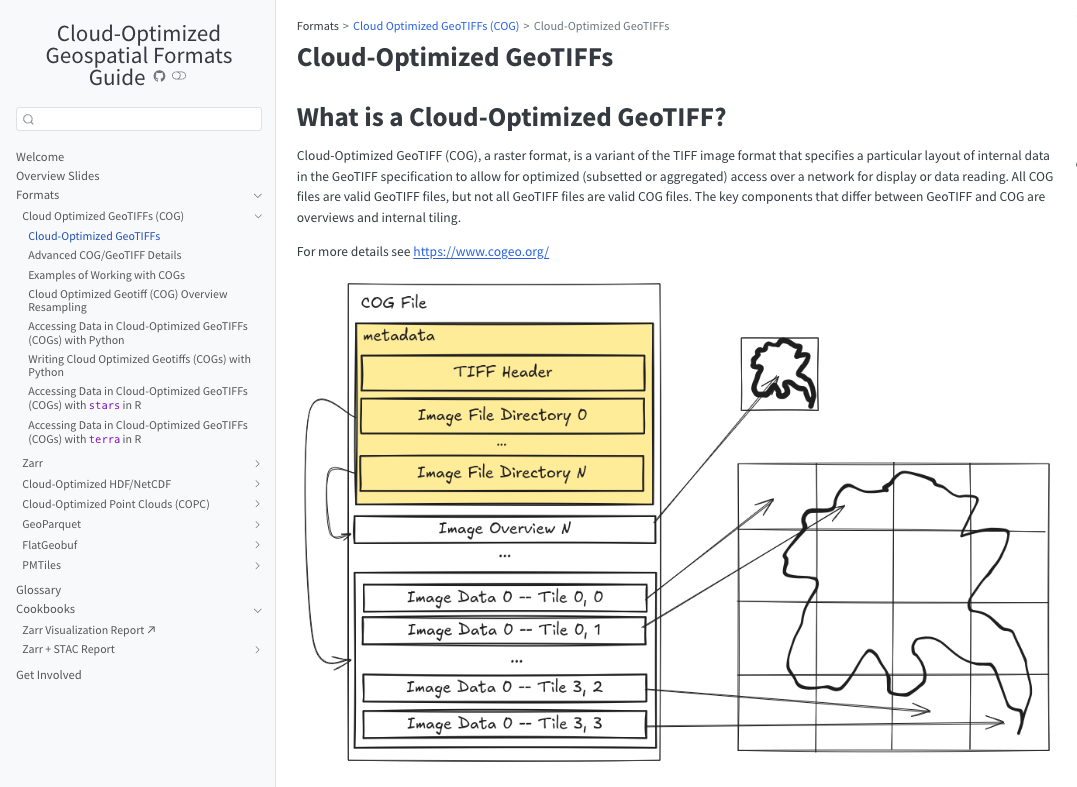

#### Required (7 pts)
**What would your reflectance values have looked like if you'd forgotten to apply the scale factor? Would that mistake be obvious, or could it silently produce a plausible-looking (but wrong) map?**

- Without the scale factor, the "reflectance" values would be the raw integers, roughly 0 to ~10,000(plus −9999 fill), instead of 0 to ~1. In a single band this mistake is fairly **obvious** if you look at the numbers, because reflectance above 1 is physically impossible. but it can produce a plausible map if you only look at images.

**Band interleave check — rasterio always returns (band, row, col)**

In [36]:
all_band_paths = sorted(glob.glob(f"{download_dir}/demo/*B0[2-5].tif"))
with rasterio.open(all_band_paths[0]) as ref:
    stack = np.stack([rasterio.open(p).read(1) for p in all_band_paths])

print("Stacked array shape (band, row, col):", stack.shape)

Stacked array shape (band, row, col): (4, 3660, 3660)


#### Required (7 pts)

In [37]:
try:
    streamed_files = earthaccess.open(clear_results[:1])
    print(f"{len(streamed_files)} file-like object(s) opened without downloading:")
    for sf in streamed_files:
        print(" ", sf)
    with rasterio.open(streamed_files[0]) as src:
        print("\nFirst file -- dtype:", src.dtypes[0], " shape:", (src.count, src.height, src.width))
except Exception as e:
    print(f"Streaming didn't work in this environment ({e}) -- that's fine, .download() above already has the data.")

QUEUEING TASKS | :   0%|          | 0/15 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/15 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/15 [00:00<?, ?it/s]

15 file-like object(s) opened without downloading:
  <File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023024T183428.v2.0/HLS.L30.T11SKU.2023024T183428.v2.0.B09.tif>
  <File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023024T183428.v2.0/HLS.L30.T11SKU.2023024T183428.v2.0.VAA.tif>
  <File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023024T183428.v2.0/HLS.L30.T11SKU.2023024T183428.v2.0.B05.tif>
  <File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023024T183428.v2.0/HLS.L30.T11SKU.2023024T183428.v2.0.B04.tif>
  <File-like object HTTPFileSystem, https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/HLSL30.020/HLS.L30.T11SKU.2023024T183428.v2.0/HLS.L30.T11SKU.2023024T183428.v2.0.B02.tif>
  <File-l